# Lab 07 — Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Student:** Saud Ahmed  
**Registration No.:** FA23-BAI-018  
**Platform:** Google Colab  
**Dataset:** Medical MNIST (Kaggle: `andrewmvd/medical-mnist`)

> **Important result-integrity note:** This notebook is designed to target strong performance, but it cannot guarantee 85%+ accuracy before execution. All results, graphs, and tables must be generated by running the cells in Colab. Do not fill the report with invented scores.

## 1. Assignment objective
Compare:
1. **Baseline:** HOG features + RBF SVM.
2. **Proposed:** HOG features + Genetic Algorithm (GA) feature selection + RBF SVM.

The assignment requires identical fixed data splits, validation-based selection, two GA settings, final test evaluation only after model selection, accuracy/macro-F1/balanced accuracy/time comparisons, GA fitness plots, feature-count comparison, and a discussion of strengths, limitations, and cost.

## 2. Why this dataset?
Medical MNIST is a public Kaggle medical-image dataset with six image categories. It is a practical first choice for a classical HOG + SVM experiment and is commonly used for medical-image classification exercises. The experiment uses a **stratified, fixed, reproducible sample** so HOG extraction and GA search can finish within a Colab session. This is a sampled experiment, not a claim that every image in the full dataset was used.

Kaggle dataset page: https://www.kaggle.com/datasets/andrewmvd/medical-mnist

## 3. Experimental design
- Image size: **128 × 128**, grayscale.
- HOG orientations: **9**.
- Pixels per cell: **8 × 8**.
- Cells per block: **2 × 2**.
- Block normalization: **L2-Hys**.
- Classifier: **RBF SVM**.
- Split: **60% train / 20% validation / 20% test**, stratified with fixed seed.
- Dataset sample: up to **500 images per class** (maximum 3,000 total).
- GA fitness: validation macro-F1 minus a feature-count penalty.
- Feature pre-filtering: use training data only to rank HOG dimensions and retain up to 512 candidate dimensions before GA search. GA then selects a subset of those HOG features. This reduces search cost while remaining a feature-selection approach.
- Test set: used once at the end to compare the selected baseline and GA model.

The GA settings below differ in population size and mutation probability. Their validation results select the final GA configuration. The test set is not used for GA fitness or hyperparameter selection.

---

# Google Colab notebook cells

## Cell 1 — Install dependencies

In [1]:
!pip -q install kagglehub scikit-image scikit-learn pandas matplotlib seaborn tqdm

## Cell 2 — Imports and reproducibility

In [2]:
import os, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm
from skimage.feature import hog

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, classification_report,
    cohen_kappa_score, matthews_corrcoef
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Reproducibility seed:", SEED)

NumPy: 2.1.3
Reproducibility seed: 42


## Cell 3 — Download the Kaggle dataset directly

In [3]:
import kagglehub

DATASET_PATH = kagglehub.dataset_download("andrewmvd/medical-mnist")
print("Dataset downloaded to:", DATASET_PATH)

# List a few paths to verify the download.
for root, dirs, files in os.walk(DATASET_PATH):
    print("Folder:", root, "| files:", len(files))
    if root.count(os.sep) - DATASET_PATH.count(os.sep) >= 1:
        dirs[:] = []

100%|██████████| 84.8M/84.8M [00:02<00:00, 33.7MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1 | files: 0
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1/Hand | files: 10000
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1/CXR | files: 10000
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1/BreastMRI | files: 8954
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1/HeadCT | files: 10000
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1/ChestCT | files: 10000
Folder: /root/.cache/kagglehub/datasets/andrewmvd/medical-mnist/versions/1/AbdomenCT | files: 10000


If KaggleHub requests authentication in your Colab session, create a Kaggle API token from your Kaggle account, upload `kaggle.json` privately to the Colab session, and configure it as shown below. Do not upload `kaggle.json` to GitHub or include it in your submission.

**Optional authentication fallback cell (run only if Cell 3 fails):**

In [4]:
# Uncomment and run only if KaggleHub requires authentication.
# from google.colab import files
# uploaded = files.upload()  # select kaggle.json from your computer
# os.makedirs("/root/.kaggle", exist_ok=True)
# import shutil
# shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
# os.chmod("/root/.kaggle/kaggle.json", 0o600)
# !pip -q install kaggle
# !kaggle datasets download -d andrewmvd/medical-mnist -p /content/medical_mnist --unzip
# DATASET_PATH = "/content/medical_mnist"

## Cell 4 — Find class folders and build a balanced sample

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
dataset_root = Path(DATASET_PATH)

# Find directories containing images; each immediate class folder is expected
# to contain image files. This avoids hardcoding the extraction directory.
class_dirs = []
for p in dataset_root.rglob("*"):
    if p.is_dir():
        try:
            image_files = [x for x in p.iterdir() if x.is_file() and x.suffix.lower() in IMAGE_EXTS]
        except PermissionError:
            continue
        if len(image_files) > 0:
            class_dirs.append((p, image_files))

# Keep only class directories that do not themselves contain child class folders
# with images. For this dataset, the six category folders should be found.
class_map = {}
for folder, imgs in class_dirs:
    class_map[str(folder)] = imgs

if len(class_map) < 2:
    raise RuntimeError(
        "Could not find at least two image-containing class folders. "
        f"Inspect DATASET_PATH={DATASET_PATH} and adjust the folder parsing."
    )

print("Candidate class folders:", len(class_map))
for folder, imgs in class_dirs:
    print(Path(folder).name, "->", len(imgs), "images")

MAX_PER_CLASS = 500
records = []
for folder, imgs in sorted(class_dirs, key=lambda x: str(x[0])):
    # Ignore a folder if a nested image folder exists below it; use leaf folders.
    has_nested_image_folder = any(
        str(other[0]).startswith(str(folder) + os.sep) for other in class_dirs
    )
    if has_nested_image_folder:
        continue
    imgs = sorted(imgs)
    rng = random.Random(SEED)
    rng.shuffle(imgs)
    chosen = imgs[:MAX_PER_CLASS]
    label = Path(folder).name
    records.extend({"path": str(p), "label": label} for p in chosen)

df = pd.DataFrame(records).drop_duplicates("path").reset_index(drop=True)
if df.empty or df["label"].nunique() < 2:
    raise RuntimeError("No usable class folders were detected. Print the directory tree and update the parser.")

print("\\nSample count:", len(df))
print("Classes:", sorted(df["label"].unique()))
display(df.groupby("label").size().rename("sample_count").to_frame())

Candidate class folders: 6
Hand -> 10000 images
CXR -> 10000 images
BreastMRI -> 8954 images
HeadCT -> 10000 images
ChestCT -> 10000 images
AbdomenCT -> 10000 images
\nSample count: 3000
Classes: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']


,sample_count
label,
AbdomenCT,500
BreastMRI,500
CXR,500
ChestCT,500
Hand,500
HeadCT,500


## Cell 5 — Visualize the sample and class balance

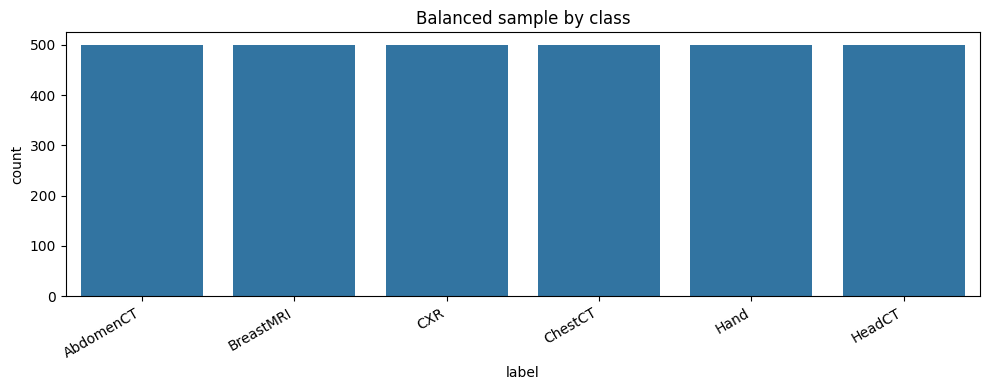

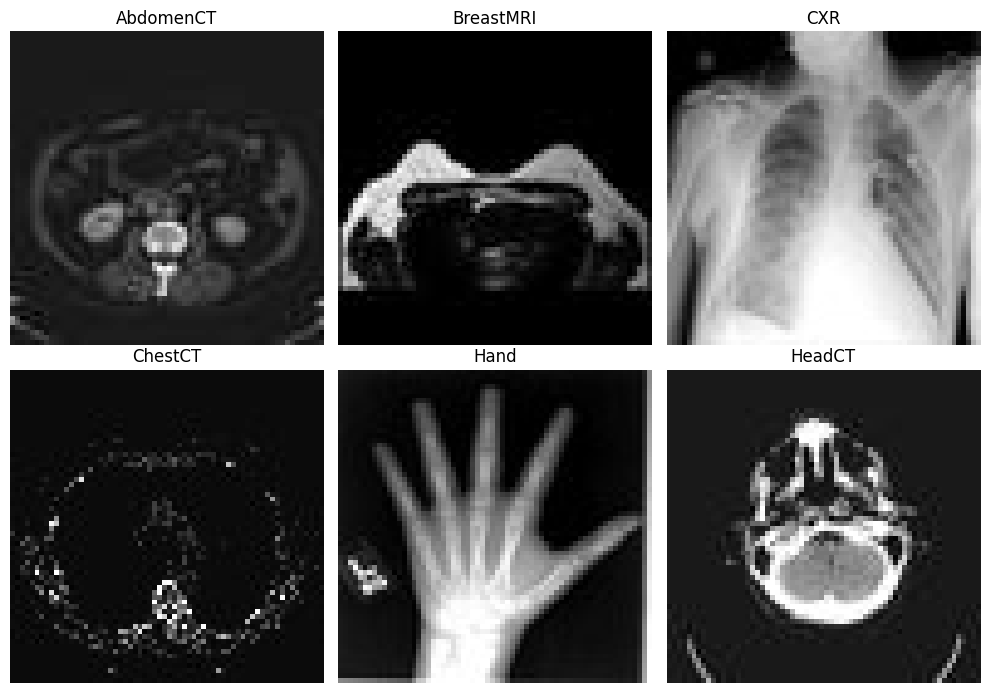

In [6]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="label", order=sorted(df["label"].unique()))
plt.title("Balanced sample by class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (_, row) in zip(axes.flat, df.groupby("label", sort=True).head(1).iterrows()):
    img = Image.open(row["path"]).convert("L")
    ax.imshow(img, cmap="gray")
    ax.set_title(row["label"])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Cell 6 — Preprocess images to 128 × 128 grayscale

In [7]:
IMAGE_SIZE = (128, 128)

def load_preprocess_image(path):
    with Image.open(path) as im:
        im = im.convert("L").resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        arr = np.asarray(im, dtype=np.uint8)
    return arr

images, labels = [], []
bad_files = []
for row in tqdm(df.itertuples(index=False), total=len(df), desc="Loading images"):
    try:
        images.append(load_preprocess_image(row.path))
        labels.append(row.label)
    except Exception as e:
        bad_files.append((row.path, str(e)))

X_images = np.stack(images)
y_text = np.asarray(labels)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_

print("Image tensor:", X_images.shape)
print("Encoded labels:", y.shape)
print("Class names:", list(class_names))
print("Unreadable files skipped:", len(bad_files))

Loading images:   0%|          | 0/3000 [00:00<?, ?it/s]

Image tensor: (3000, 128, 128)
Encoded labels: (3000,)
Class names: [np.str_('AbdomenCT'), np.str_('BreastMRI'), np.str_('CXR'), np.str_('ChestCT'), np.str_('Hand'), np.str_('HeadCT')]
Unreadable files skipped: 0


## Cell 7 — Fixed stratified train/validation/test split

In [8]:
indices = np.arange(len(y))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.40, random_state=SEED, stratify=y
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=y[temp_idx]
)

X_train_img, y_train = X_images[train_idx], y[train_idx]
X_val_img, y_val = X_images[val_idx], y[val_idx]
X_test_img, y_test = X_images[test_idx], y[test_idx]

print(f"Train: {len(train_idx)} ({len(train_idx)/len(y):.1%})")
print(f"Validation: {len(val_idx)} ({len(val_idx)/len(y):.1%})")
print(f"Test: {len(test_idx)} ({len(test_idx)/len(y):.1%})")

split_summary = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "validation": pd.Series(y_val).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index()
})
split_summary.index = class_names
display(split_summary)

Train: 1800 (60.0%)
Validation: 600 (20.0%)
Test: 600 (20.0%)


,train,validation,test
AbdomenCT,300,100,100
BreastMRI,300,100,100
CXR,300,100,100
ChestCT,300,100,100
Hand,300,100,100
HeadCT,300,100,100


## Cell 8 — Extract HOG features

In [9]:
HOG_PARAMS = dict(
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    transform_sqrt=True,
    feature_vector=True
)

def extract_hog_batch(image_array, description):
    rows = []
    for img in tqdm(image_array, desc=description):
        features = hog(img, **HOG_PARAMS)
        rows.append(features.astype(np.float32))
    return np.vstack(rows)

hog_start = time.perf_counter()
X_train_hog = extract_hog_batch(X_train_img, "HOG train")
X_val_hog = extract_hog_batch(X_val_img, "HOG validation")
X_test_hog = extract_hog_batch(X_test_img, "HOG test")
hog_extraction_seconds = time.perf_counter() - hog_start

print("Train HOG shape:", X_train_hog.shape)
print("Validation HOG shape:", X_val_hog.shape)
print("Test HOG shape:", X_test_hog.shape)
print(f"Total HOG extraction time: {hog_extraction_seconds:.2f} seconds")

HOG train:   0%|          | 0/1800 [00:00<?, ?it/s]

HOG validation:   0%|          | 0/600 [00:00<?, ?it/s]

HOG test:   0%|          | 0/600 [00:00<?, ?it/s]

Train HOG shape: (1800, 8100)
Validation HOG shape: (600, 8100)
Test HOG shape: (600, 8100)
Total HOG extraction time: 20.29 seconds


## Cell 9 — Scale HOG features using training data only

In [10]:
# Fit scaler only on training features to prevent data leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_hog).astype(np.float32)
X_val_scaled = scaler.transform(X_val_hog).astype(np.float32)
X_test_scaled = scaler.transform(X_test_hog).astype(np.float32)

print("Scaled feature dimension:", X_train_scaled.shape[1])

Scaled feature dimension: 8100


## Cell 10 — Helper functions and baseline SVM tuning on validation

In [11]:
def metric_dict(y_true, y_pred):
    # Macro specificity: calculate one-vs-rest specificity for each class, then average.
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    specificities = []
    total = cm.sum()
    for i in range(len(class_names)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp
        specificities.append(tn / (tn + fp) if (tn + fp) else 0.0)

    return {
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Precision Macro (%)": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall Macro (%)": 100 * recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro-F1 (%)": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted-F1 (%)": 100 * f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y_true, y_pred),
        "Specificity Macro (%)": 100 * float(np.mean(specificities)),
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred)
    }

# Keep the search modest for Colab. Select using validation macro-F1 only.
baseline_candidates = [
    {"C": 1, "gamma": "scale"},
    {"C": 5, "gamma": "scale"},
    {"C": 10, "gamma": "scale"},
]
baseline_tuning_rows = []
best_baseline = None
best_baseline_f1 = -1

for params in baseline_candidates:
    model = SVC(kernel="rbf", C=params["C"], gamma=params["gamma"], cache_size=1000)
    t0 = time.perf_counter()
    model.fit(X_train_scaled, y_train)
    fit_seconds = time.perf_counter() - t0
    val_pred = model.predict(X_val_scaled)
    val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
    baseline_tuning_rows.append({**params, "validation_macro_f1": val_f1, "fit_seconds": fit_seconds})
    if val_f1 > best_baseline_f1:
        best_baseline_f1 = val_f1
        best_baseline = model
        best_baseline_params = params

baseline_tuning_df = pd.DataFrame(baseline_tuning_rows)
display(baseline_tuning_df)
print("Selected baseline parameters:", best_baseline_params)
print(f"Best validation macro-F1: {best_baseline_f1:.4f}")

,C,gamma,validation_macro_f1,fit_seconds
0,1,scale,0.998333,9.967909
1,5,scale,0.998333,9.940414
2,10,scale,0.998333,10.007015


Selected baseline parameters: {'C': 1, 'gamma': 'scale'}
Best validation macro-F1: 0.9983


## Cell 11 — Training-only HOG feature pre-filter for GA

In [12]:
# Rank dimensions with ANOVA F-score using training data ONLY.
# This is a computational pre-filter; the GA still selects the final subset.
f_scores, _ = f_classif(X_train_scaled, y_train)
f_scores = np.nan_to_num(f_scores, nan=0.0, posinf=0.0, neginf=0.0)

N_CANDIDATES = min(512, X_train_scaled.shape[1])
candidate_idx = np.argsort(f_scores)[-N_CANDIDATES:]
candidate_idx = np.sort(candidate_idx)

Xtr_cand = X_train_scaled[:, candidate_idx]
Xval_cand = X_val_scaled[:, candidate_idx]
Xtest_cand = X_test_scaled[:, candidate_idx]

print("Original HOG features:", X_train_scaled.shape[1])
print("GA candidate features after training-only pre-filter:", len(candidate_idx))

Original HOG features: 8100
GA candidate features after training-only pre-filter: 512


## Cell 12 — Genetic Algorithm implementation

In [13]:
def evaluate_chromosome(chromosome, Xtr, ytr, Xv, yv, C=5, feature_penalty=0.03):
    selected = np.flatnonzero(chromosome)
    if len(selected) == 0:
        return 0.0, 0.0, 0

    clf = SVC(kernel="rbf", C=C, gamma="scale", cache_size=500)
    clf.fit(Xtr[:, selected], ytr)
    pred = clf.predict(Xv[:, selected])
    macro_f1 = f1_score(yv, pred, average="macro", zero_division=0)

    # Penalty is proportional to selected fraction; it encourages compact solutions.
    fraction_selected = len(selected) / chromosome.size
    fitness = macro_f1 - feature_penalty * fraction_selected
    return fitness, macro_f1, len(selected)


def run_genetic_algorithm(
    Xtr, ytr, Xv, yv,
    population_size=10,
    generations=8,
    mutation_rate=0.03,
    crossover_rate=0.8,
    feature_penalty=0.03,
    seed=42
):
    rng = np.random.default_rng(seed)
    n_features = Xtr.shape[1]

    # Sparse-ish initial population: each feature has 20% chance of being selected.
    population = rng.random((population_size, n_features)) < 0.20
    # Ensure every chromosome has at least one selected feature.
    for i in range(population_size):
        if not population[i].any():
            population[i, rng.integers(0, n_features)] = True

    history = []
    best_chromosome = None
    best_fitness = -np.inf
    best_macro_f1 = 0.0

    def tournament_select(fitness_values, k=3):
        contenders = rng.choice(len(fitness_values), size=min(k, len(fitness_values)), replace=False)
        return contenders[np.argmax(fitness_values[contenders])]

    for generation in range(generations):
        fitness_values = np.zeros(population_size, dtype=float)
        f1_values = np.zeros(population_size, dtype=float)
        counts = np.zeros(population_size, dtype=int)

        for i, chromosome in enumerate(population):
            fitness_values[i], f1_values[i], counts[i] = evaluate_chromosome(
                chromosome, Xtr, ytr, Xv, yv,
                feature_penalty=feature_penalty
            )

        gen_best = int(np.argmax(fitness_values))
        if fitness_values[gen_best] > best_fitness:
            best_fitness = float(fitness_values[gen_best])
            best_chromosome = population[gen_best].copy()
            best_macro_f1 = float(f1_values[gen_best])

        history.append({
            "generation": generation + 1,
            "best_fitness": float(fitness_values[gen_best]),
            "best_validation_macro_f1": float(f1_values[gen_best]),
            "best_feature_count": int(counts[gen_best]),
            "mean_fitness": float(np.mean(fitness_values))
        })

        # Elitism: keep the best chromosome unchanged.
        new_population = [population[gen_best].copy()]
        while len(new_population) < population_size:
            p1 = population[tournament_select(fitness_values)].copy()
            p2 = population[tournament_select(fitness_values)].copy()

            if rng.random() < crossover_rate and n_features > 1:
                point = rng.integers(1, n_features)
                child1 = np.concatenate([p1[:point], p2[point:]])
                child2 = np.concatenate([p2[:point], p1[point:]])
            else:
                child1, child2 = p1.copy(), p2.copy()

            for child in (child1, child2):
                mutation_mask = rng.random(n_features) < mutation_rate
                child[mutation_mask] = ~child[mutation_mask]
                if not child.any():
                    child[rng.integers(0, n_features)] = True
                new_population.append(child)
                if len(new_population) >= population_size:
                    break

        population = np.asarray(new_population[:population_size], dtype=bool)

    # Re-evaluate final best chromosome on validation to return a consistent score.
    final_fitness, final_f1, final_count = evaluate_chromosome(
        best_chromosome, Xtr, ytr, Xv, yv, feature_penalty=feature_penalty
    )
    return {
        "mask": best_chromosome,
        "fitness": final_fitness,
        "validation_macro_f1": final_f1,
        "selected_count": final_count,
        "history": pd.DataFrame(history)
    }

## Cell 13 — Run GA

In [14]:
ga_settings = [
    {
        "name": "GA-A: small population",
        "population_size": 8,
        "generations": 6,
        "mutation_rate": 0.02,
        "seed": SEED
    },
    {
        "name": "GA-B: larger population / mutation",
        "population_size": 12,
        "generations": 8,
        "mutation_rate": 0.04,
        "seed": SEED + 1
    }
]

ga_runs = []
for setting in ga_settings:
    print("\\nRunning:", setting["name"])
    start = time.perf_counter()
    result = run_genetic_algorithm(
        Xtr_cand, y_train, Xval_cand, y_val,
        population_size=setting["population_size"],
        generations=setting["generations"],
        mutation_rate=setting["mutation_rate"],
        feature_penalty=0.03,
        seed=setting["seed"]
    )
    elapsed = time.perf_counter() - start
    result["name"] = setting["name"]
    result["settings"] = setting
    result["ga_seconds"] = elapsed
    ga_runs.append(result)
    print("Validation macro-F1:", round(result["validation_macro_f1"], 4))
    print("Selected candidate features:", result["selected_count"], "/", len(candidate_idx))
    print("GA time (seconds):", round(elapsed, 2))

ga_summary = pd.DataFrame([
    {
        "GA setting": r["name"],
        "Population": r["settings"]["population_size"],
        "Generations": r["settings"]["generations"],
        "Mutation rate": r["settings"]["mutation_rate"],
        "Validation macro-F1 (%)": 100 * r["validation_macro_f1"],
        "Selected features": r["selected_count"],
        "GA time (seconds)": r["ga_seconds"]
    } for r in ga_runs
])
display(ga_summary)

# Select GA setting strictly by validation macro-F1.
best_ga = max(ga_runs, key=lambda r: r["validation_macro_f1"])
best_mask = best_ga["mask"]
print("Selected GA configuration:", best_ga["name"])
print("Selected features:", int(best_mask.sum()))

\nRunning: GA-A: small population
Validation macro-F1: 0.9851
Selected candidate features: 104 / 512
GA time (seconds): 6.88
\nRunning: GA-B: larger population / mutation
Validation macro-F1: 0.9933
Selected candidate features: 125 / 512
GA time (seconds): 16.88


,GA setting,Population,Generations,Mutation rate,Validation macro-F1 (%),Selected features,GA time (seconds)
0,GA-A: small population,8,6,0.02,98.508572,104,6.881508
1,GA-B: larger population / mutation,12,8,0.04,99.334926,125,16.879032


Selected GA configuration: GA-B: larger population / mutation
Selected features: 125


## Cell 14 — Plot GA fitness across generations

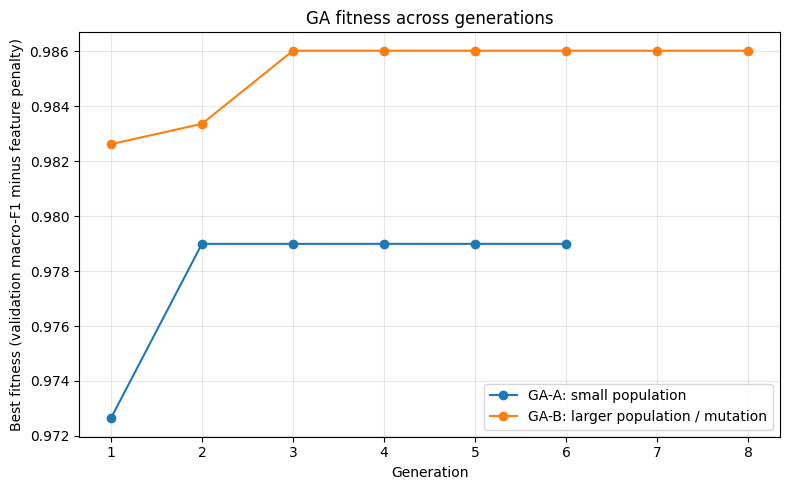

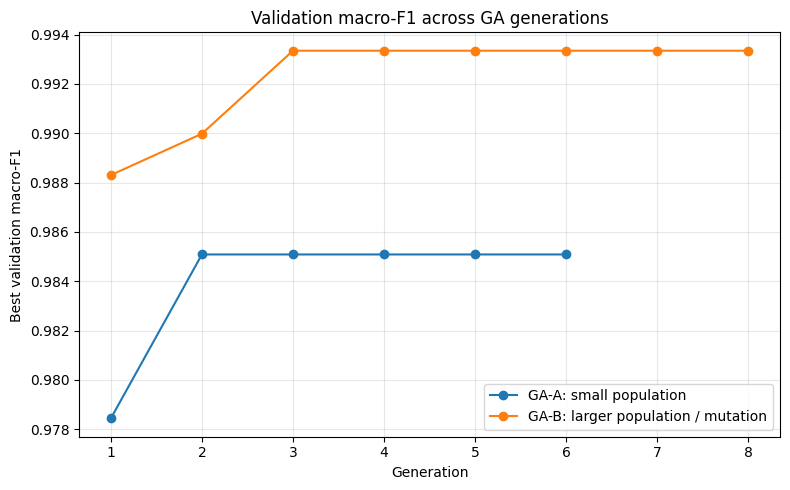

In [15]:
plt.figure(figsize=(8, 5))
for run in ga_runs:
    h = run["history"]
    plt.plot(h["generation"], h["best_fitness"], marker="o", label=run["name"])
plt.xlabel("Generation")
plt.ylabel("Best fitness (validation macro-F1 minus feature penalty)")
plt.title("GA fitness across generations")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for run in ga_runs:
    h = run["history"]
    plt.plot(h["generation"], h["best_validation_macro_f1"], marker="o", label=run["name"])
plt.xlabel("Generation")
plt.ylabel("Best validation macro-F1")
plt.title("Validation macro-F1 across GA generations")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Cell 15 — Fit selected GA-HOG + SVM model

In [16]:
selected_candidate_idx = np.flatnonzero(best_mask)
selected_original_hog_idx = candidate_idx[selected_candidate_idx]

Xtr_ga = X_train_scaled[:, selected_original_hog_idx]
Xval_ga = X_val_scaled[:, selected_original_hog_idx]
Xtest_ga = X_test_scaled[:, selected_original_hog_idx]

# Use the same RBF SVM family and choose C on validation only.
ga_svm_candidates = [1, 5, 10]
ga_tuning_rows = []
best_ga_model = None
best_ga_val_f1 = -1

for C in ga_svm_candidates:
    model = SVC(kernel="rbf", C=C, gamma="scale", cache_size=1000)
    t0 = time.perf_counter()
    model.fit(Xtr_ga, y_train)
    fit_seconds = time.perf_counter() - t0
    pred = model.predict(Xval_ga)
    val_f1 = f1_score(y_val, pred, average="macro", zero_division=0)
    ga_tuning_rows.append({"C": C, "validation_macro_f1": val_f1, "fit_seconds": fit_seconds})
    if val_f1 > best_ga_val_f1:
        best_ga_val_f1 = val_f1
        best_ga_model = model
        best_ga_C = C

display(pd.DataFrame(ga_tuning_rows))
print("Selected GA-SVM C:", best_ga_C)
print(f"Selected GA validation macro-F1: {best_ga_val_f1:.4f}")

,C,validation_macro_f1,fit_seconds
0,1,0.985112,0.137529
1,5,0.993349,0.088051
2,10,0.990032,0.090287


Selected GA-SVM C: 5
Selected GA validation macro-F1: 0.9933


## Cell 16 — Final test evaluation

In [17]:
# The test set is first used here, after baseline and GA settings have been selected.
baseline_test_start = time.perf_counter()
baseline_test_pred = best_baseline.predict(X_test_scaled)
baseline_prediction_seconds = time.perf_counter() - baseline_test_start

ga_test_start = time.perf_counter()
ga_test_pred = best_ga_model.predict(Xtest_ga)
ga_prediction_seconds = time.perf_counter() - ga_test_start

baseline_metrics = metric_dict(y_test, baseline_test_pred)
ga_metrics = metric_dict(y_test, ga_test_pred)

results = pd.DataFrame(
    {"HOG + SVM (Baseline)": baseline_metrics,
     "GA-HOG + SVM (Proposed)": ga_metrics}
)
results["Improvement (GA - Baseline)"] = (
    results["GA-HOG + SVM (Proposed)"] - results["HOG + SVM (Baseline)"]
)
display(results.round(4))

print("\\nBaseline classification report")
print(classification_report(y_test, baseline_test_pred, target_names=class_names, zero_division=0))
print("\\nGA-HOG classification report")
print(classification_report(y_test, ga_test_pred, target_names=class_names, zero_division=0))

,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement (GA - Baseline)
Accuracy (%),99.8333,97.5000,-2.3333
Precision Macro (%),99.8350,97.5226,-2.3124
Recall Macro (%),99.8333,97.5000,-2.3333
Macro-F1 (%),99.8333,97.4977,-2.3356
Weighted-F1 (%),99.8333,97.4977,-2.3356
Balanced accuracy (%),99.8333,97.5000,-2.3333
Specificity Macro (%),99.9667,99.5000,-0.4667
Cohen's kappa,0.9980,0.9700,-0.0280
Matthews correlation coefficient,0.9980,0.9701,-0.0279


\nBaseline classification report
              precision    recall  f1-score   support

   AbdomenCT       1.00      1.00      1.00       100
   BreastMRI       1.00      1.00      1.00       100
         CXR       1.00      1.00      1.00       100
     ChestCT       1.00      1.00      1.00       100
        Hand       1.00      0.99      0.99       100
      HeadCT       0.99      1.00      1.00       100

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600

\nGA-HOG classification report
              precision    recall  f1-score   support

   AbdomenCT       0.94      0.98      0.96       100
   BreastMRI       0.97      0.98      0.98       100
         CXR       0.99      0.99      0.99       100
     ChestCT       0.97      0.93      0.95       100
        Hand       1.00      0.99      0.99       100
      HeadCT       0.98      0.98      0.98       100

    accuracy 

## Cell 17 — Compare feature counts and computational time

,Model,HOG dimensions used,Feature reduction (%),HOG extraction time (s),Model fit time (s),GA search time (s),Final test prediction time (s)
0,HOG + SVM (Baseline),8100,0.000,20.291,29.915,0.000,6.035
1,GA-HOG + SVM (Proposed),125,98.457,20.291,0.316,16.879,0.074


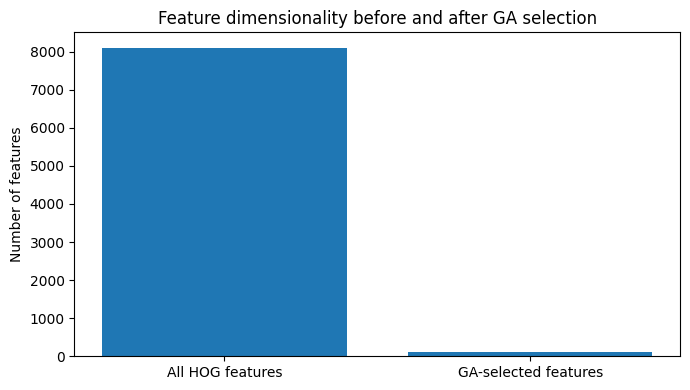

<Figure size 900x500 with 0 Axes>

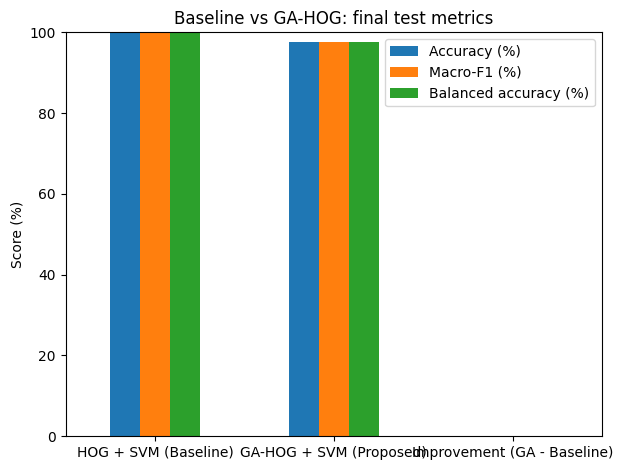

In [18]:
original_feature_count = X_train_scaled.shape[1]
ga_feature_count = len(selected_original_hog_idx)
feature_reduction_pct = 100 * (1 - ga_feature_count / original_feature_count)

time_comparison = pd.DataFrame([
    {
        "Model": "HOG + SVM (Baseline)",
        "HOG dimensions used": original_feature_count,
        "Feature reduction (%)": 0.0,
        "HOG extraction time (s)": hog_extraction_seconds,
        "Model fit time (s)": sum(baseline_tuning_df["fit_seconds"]),
        "GA search time (s)": 0.0,
        "Final test prediction time (s)": baseline_prediction_seconds
    },
    {
        "Model": "GA-HOG + SVM (Proposed)",
        "HOG dimensions used": ga_feature_count,
        "Feature reduction (%)": feature_reduction_pct,
        "HOG extraction time (s)": hog_extraction_seconds,
        "Model fit time (s)": sum(row["fit_seconds"] for row in ga_tuning_rows),
        "GA search time (s)": best_ga["ga_seconds"],
        "Final test prediction time (s)": ga_prediction_seconds
    }
])
display(time_comparison.round(3))

plt.figure(figsize=(7, 4))
plt.bar(["All HOG features", "GA-selected features"],
        [original_feature_count, ga_feature_count])
plt.ylabel("Number of features")
plt.title("Feature dimensionality before and after GA selection")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
results.loc[["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)"]].T.plot(kind="bar")
plt.ylabel("Score (%)")
plt.title("Baseline vs GA-HOG: final test metrics")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Cell 18 — Confusion matrices

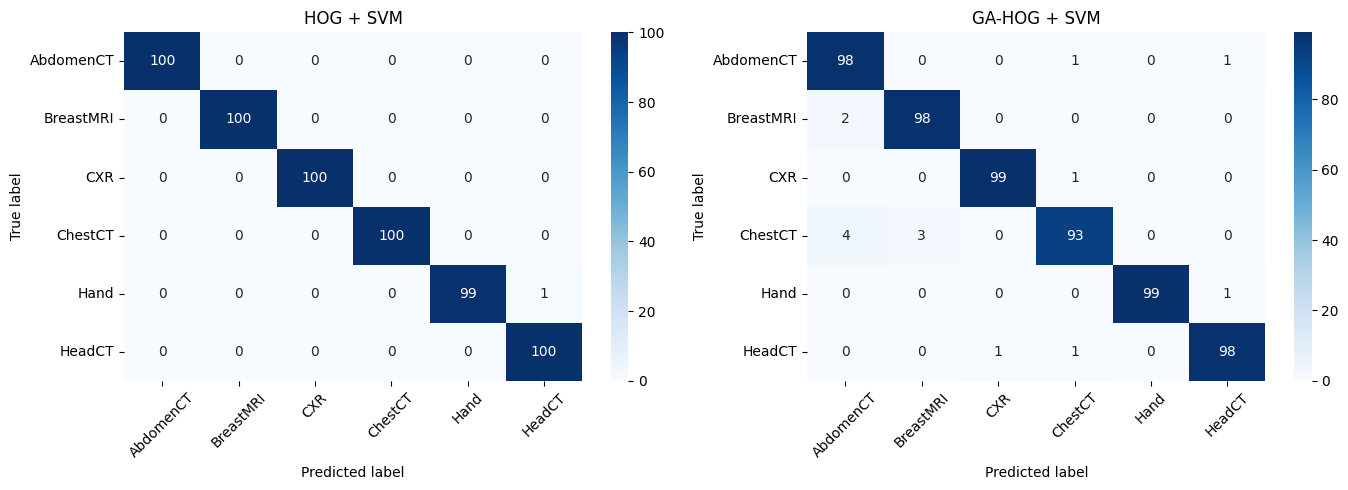

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, title in [
    (axes[0], baseline_test_pred, "HOG + SVM"),
    (axes[1], ga_test_pred, "GA-HOG + SVM")
]:
    cm = confusion_matrix(y_test, pred, labels=np.arange(len(class_names)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

## Cell 19 — Save results, plots, and metadata

In [20]:
OUTPUT_DIR = Path("/content/lab07_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results.to_csv(OUTPUT_DIR / "model_comparison.csv")
ga_summary.to_csv(OUTPUT_DIR / "ga_settings_comparison.csv", index=False)
time_comparison.to_csv(OUTPUT_DIR / "computational_time_and_features.csv", index=False)
baseline_tuning_df.to_csv(OUTPUT_DIR / "baseline_validation_tuning.csv", index=False)
pd.DataFrame(ga_tuning_rows).to_csv(OUTPUT_DIR / "ga_svm_validation_tuning.csv", index=False)

metadata = {
    "dataset": "Kaggle Medical MNIST (andrewmvd/medical-mnist)",
    "random_seed": SEED,
    "image_size": "128x128 grayscale",
    "hog_orientations": 9,
    "pixels_per_cell": "8x8",
    "cells_per_block": "2x2",
    "block_norm": "L2-Hys",
    "classifier": "RBF SVM",
    "train_samples": len(y_train),
    "validation_samples": len(y_val),
    "test_samples": len(y_test),
    "original_hog_features": int(original_feature_count),
    "ga_candidate_features": int(len(candidate_idx)),
    "ga_selected_features": int(ga_feature_count),
    "feature_reduction_percent": float(feature_reduction_pct),
    "selected_ga_configuration": best_ga["name"],
    "selected_ga_population": int(best_ga["settings"]["population_size"]),
    "selected_ga_generations": int(best_ga["settings"]["generations"]),
    "selected_ga_mutation_rate": float(best_ga["settings"]["mutation_rate"])
}
pd.Series(metadata).to_json(OUTPUT_DIR / "experiment_metadata.json", indent=2)

# Save plots
plt.figure(figsize=(8, 5))
for run in ga_runs:
    h = run["history"]
    plt.plot(h["generation"], h["best_fitness"], marker="o", label=run["name"])
plt.xlabel("Generation"); plt.ylabel("Best fitness"); plt.title("GA fitness across generations")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ga_fitness.png", dpi=160); plt.close()

plt.figure(figsize=(7, 4))
plt.bar(["All HOG features", "GA-selected features"], [original_feature_count, ga_feature_count])
plt.ylabel("Number of features"); plt.title("Feature count before and after GA")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "feature_reduction.png", dpi=160); plt.close()

print("Saved outputs to:", OUTPUT_DIR)
print("\\nFiles:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

Saved outputs to: /content/lab07_outputs
\nFiles:
- baseline_validation_tuning.csv
- computational_time_and_features.csv
- experiment_metadata.json
- feature_reduction.png
- ga_fitness.png
- ga_settings_comparison.csv
- ga_svm_validation_tuning.csv
- model_comparison.csv


## Cell 20 — Download the result bundle

In [21]:
import shutil
zip_path = shutil.make_archive("/content/Lab07_results", "zip", OUTPUT_DIR)
print("Created:", zip_path)

from google.colab import files
files.download(zip_path)

Created: /content/Lab07_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>